# 13. Neumann, Robin and mixed boundary conditions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/13_boundary_conditions.ipynb)

*Companion to Chapter 13 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Up to now nearly every boundary has had a prescribed value. Real boundaries are more varied: an
insulated wall fixes the gradient, a surface cooled by a fluid links the gradient to the
value, the free end of a bar carries no force, and an open end should let waves out without
sending anything back. One idea covers them all, and it costs a line or two of code for each
boundary.

- the principle: a boundary condition replaces the equation in the row of its boundary point
- Neumann and Robin conditions in a steady problem and in an eigenvalue problem
- mixed conditions on the sides of a square, in the Kronecker system of notebook 6
- fixed, free and absorbing ends for a wave

**Worked examples:** a fin that loses heat from its tip, the cooling of a slab by convection
(the theory behind the Heisler charts), a plate heated along one side with two sides
insulated, and a pulse meeting three kinds of end.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.linalg import eig
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))
    D -= np.diag(D.sum(axis=1))
    return D, x

# barycentric_interpolate(values, x_eval) from notebook 4: evaluates the interpolant between the grid points
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

# clenshaw_curtis(N) from notebook 10: weights w_j with ∫ f dx ≈ Σ w_j f(x_j) on the Chebyshev points
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)
    w = dct(moments, type=1) / N
    w[0] /= 2
    w[N] /= 2
    return x, w

## 13.1 The principle

In notebook 6 the boundary values were known, so the boundary points were removed from the
list of unknowns. That works only for Dirichlet conditions. The general approach keeps all
$N + 1$ grid values as unknowns and writes $N + 1$ equations:

- at each interior point, the differential equation, which is that point's row of the matrix;
- at each boundary point, **the boundary condition instead**.

With the Chebyshev ordering, index 0 is $x = +1$ and index $N$ is $x = -1$, so the boundary
rows are the first and the last. The boundary condition at $x = +1$ becomes row 0 as follows.

| Condition at $x = 1$ | Physical meaning | Row 0 of the matrix | Right-hand side |
| --- | --- | --- | --- |
| Dirichlet, $u = a$ | fixed temperature, fixed end | row 0 of the identity | $a$ |
| Neumann, $u' = b$ | prescribed flux; insulated if $b = 0$ | row 0 of $D$ | $b$ |
| Robin, $u' + \mathrm{Bi}\,u = c$ | convection to a fluid, a spring | row 0 of $D$ plus $\mathrm{Bi}$ times row 0 of the identity | $c$ |

Row 0 of $D$ gives the derivative of the interpolating polynomial at $x = 1$ from **all** the
grid values, with spectral accuracy. A finite difference code would use a one-sided formula or
a ghost point here, and has to take care not to lose an order of accuracy. Here nothing is lost.

## 13.2 Worked example: a fin that loses heat from its tip

**Problem.** Notebook 5 looked at a fin with an insulated tip. A real fin also loses heat from
its end face. In dimensionless form, with $x$ from the base to the tip,

$$\theta'' = m^2\theta,\qquad \theta(0) = 1,\qquad \theta'(1) + \mathrm{Bi}\,\theta(1) = 0 .$$

Here $\mathrm{Bi} = hL/k$ is the Biot number based on the fin length. For a pin fin of diameter
$d$, $m^2 = 4hL^2/(kd)$, so $\mathrm{Bi} = m^2 d/(4L)$. Take $m = 3$ and $d/L = 0.1$, which gives
$\mathrm{Bi} = 0.225$. How much more heat leaves the base than the insulated-tip formula
$m\tanh m$ predicts?

**By hand.** The general solution is $A\cosh m(1-x) + B\sinh m(1-x)$. The tip condition gives
$B = (\mathrm{Bi}/m)\,A$ and the base condition fixes $A$:

$$\theta(x) = \frac{\cosh m(1-x) + (\mathrm{Bi}/m)\sinh m(1-x)}{\cosh m + (\mathrm{Bi}/m)\sinh m},\qquad
-\theta'(0) = m\,\frac{\sinh m + (\mathrm{Bi}/m)\cosh m}{\cosh m + (\mathrm{Bi}/m)\sinh m} .$$

The grid is mapped to $[0, 1]$, which multiplies $D$ by 2. The tip $x = 1$ is index 0 and the
base $x = 0$ is index $N$.

In [3]:
def solve_fin(N, m, Bi):
    """Fin with a convecting tip. Returns the points on [0, 1], θ there and the base heat flux -θ'(0)."""
    D, xi = cheb(N)
    D, x = 2 * D, (xi + 1) / 2                       # map [-1, 1] to [0, 1]
    A = D @ D - m**2 * np.eye(N + 1)                 # θ'' - m² θ = 0 in every row, for now
    rhs = np.zeros(N + 1)
    A[0, :] = D[0, :]                                # row 0, the tip x = 1: θ' + Bi θ = 0
    A[0, 0] += Bi
    A[N, :] = 0.0                                    # row N, the base x = 0: θ = 1
    A[N, N], rhs[N] = 1.0, 1.0
    theta = np.linalg.solve(A, rhs)
    return x, theta, -(D @ theta)[N]

def fin_exact(x, m, Bi):
    return (np.cosh(m * (1 - x)) + Bi / m * np.sinh(m * (1 - x))) / (np.cosh(m) + Bi / m * np.sinh(m))

def fin_exact_flux(m, Bi):
    return m * (np.sinh(m) + Bi / m * np.cosh(m)) / (np.cosh(m) + Bi / m * np.sinh(m))

m_fin, Bi_tip = 3.0, 0.225
print("  N   error in θ    error in base flux")
for N in (4, 8, 12, 16):
    x, theta, flux = solve_fin(N, m_fin, Bi_tip)
    print(f"{N:3d} {np.abs(theta - fin_exact(x, m_fin, Bi_tip)).max():11.1e} {abs(flux - fin_exact_flux(m_fin, Bi_tip)):14.1e}")

  N   error in θ    error in base flux
  4     4.3e-03        3.1e-02
  8     8.7e-07        4.0e-06
 12     2.4e-11        9.5e-11
 16     3.9e-14        1.3e-13


In [4]:
# Verify: the exact solution, the insulated limit Bi = 0 of notebook 5, and the boundary condition itself
x, theta, flux = solve_fin(16, m_fin, Bi_tip)
assert np.abs(theta - fin_exact(x, m_fin, Bi_tip)).max() < 1e-10 and abs(flux - fin_exact_flux(m_fin, Bi_tip)) < 1e-10
assert abs(solve_fin(16, m_fin, 0.0)[2] - m_fin * np.tanh(m_fin)) < 1e-10
assert abs((2 * cheb(16)[0] @ theta)[0] + Bi_tip * theta[0]) < 1e-10

insulated = m_fin * np.tanh(m_fin)
corrected = m_fin * np.tanh(m_fin * (1 + 0.1 / 4))        # the handbook fix: lengthen the fin by d/4, keep the tip insulated
print(f"base heat flux:  insulated tip {insulated:.5f}   convecting tip {flux:.5f}   corrected-length rule {corrected:.5f}")
print(f"tip temperature: insulated tip {1 / np.cosh(m_fin):.4f}   convecting tip {theta[0]:.4f}")

base heat flux:  insulated tip 2.98516   convecting tip 2.98723   corrected-length rule 2.98723
tip temperature: insulated tip 0.0993   convecting tip 0.0924


Seventeen points give the temperature and the base heat flux to $10^{-13}$, the same accuracy
as with Dirichlet conditions. The Robin row costs nothing.

For the engineer: tip convection raises the heat flow from the base by only 0.07 per cent,
because at $m = 3$ the tip is already close to the fluid temperature and has little left to
give. The handbook rule of lengthening the fin by $d/4$ reproduces the exact result to all the
digits printed. Tip losses matter for short, stubby fins (small $m$), and the same three lines of code
handle those.

## 13.3 Worked example: cooling of a slab by convection

**Problem.** A plate of half-thickness 1 at uniform temperature is plunged into a fluid. With
$x$ measured from the mid-plane and $\theta$ the temperature above the fluid temperature,

$$\theta_t = \theta_{xx},\qquad \theta_x(0, t) = 0 \text{ (symmetry)},\qquad
\theta_x(1, t) + \mathrm{Bi}\,\theta(1, t) = 0 \text{ (convection)} .$$

At what rates does the plate cool, as a function of the Biot number $\mathrm{Bi} = ha/k$?

**By hand.** Separate the variables: $\theta = e^{-\zeta^2 t}\phi(x)$ with $-\phi'' = \zeta^2\phi$.
The symmetry condition selects $\phi = \cos\zeta x$, and the surface condition then requires

$$\zeta\tan\zeta = \mathrm{Bi} .$$

This transcendental equation has one root in each interval $\big((n-1)\pi,\ (n-1)\pi + \pi/2\big)$.
The decay rates are $\zeta_n^2$. Every heat transfer textbook tabulates the roots; for
$\mathrm{Bi} = 1$ they are $\zeta_1 = 0.8603336$, $\zeta_2 = 3.4256185$, $\zeta_3 = 6.4372982$.

On the grid, both boundary rows are replaced, one by a Neumann and one by a Robin condition.
Neither contains the eigenvalue, so the problem is a generalized one, as for the hanging chain
of notebook 8:

$$A\,\boldsymbol{\phi} = \zeta^2\,B\,\boldsymbol{\phi},$$

with $A = -D^2$ except in the two boundary rows, and $B$ the identity with those two rows set
to zero. The two infinite eigenvalues that the singular $B$ produces are discarded. The
alternative is to solve the two boundary equations for the two boundary values and substitute,
which leaves an ordinary eigenvalue problem for the interior values. Both give the same
numbers. The generalized form is used here because the boundary rows stay visible in the
code; section 13.5 uses elimination.

In [5]:
def slab_modes(N, Bi, count=3):
    """First roots ζ_n and mode shapes for the half slab [0, 1]: symmetry at x = 0, convection at x = 1."""
    D, xi = cheb(N)
    D, x = 2 * D, (xi + 1) / 2
    A, B = -D @ D, np.eye(N + 1)
    A[0, :] = D[0, :]                                # row 0, the surface x = 1: φ' + Bi φ = 0
    A[0, 0] += Bi
    A[N, :] = D[N, :]                                # row N, the mid-plane x = 0: φ' = 0
    B[0, 0] = B[N, N] = 0.0                          # no eigenvalue in the boundary rows
    values, vectors = eig(A, B)
    keep = np.isfinite(values) & (np.abs(values.imag) < 1e-8) & (values.real > 0)
    order = np.argsort(values.real[keep])[:count]
    return np.sqrt(values.real[keep][order]), vectors.real[:, keep][:, order], x

def zeta_exact(Bi, n):
    """n-th root of ζ tan ζ = Bi by bracketing, written as ζ sin ζ - Bi cos ζ = 0 to avoid the poles."""
    return brentq(lambda z: z * np.sin(z) - Bi * np.cos(z), (n - 1) * np.pi, (n - 1) * np.pi + np.pi / 2)

zeta, modes, x = slab_modes(24, 1.0)
reference = np.array([zeta_exact(1.0, n) for n in (1, 2, 3)])
print("  n    computed ζ_n     root finder      decay rate ζ_n²")
for n in range(3):
    print(f"{n + 1:3d} {zeta[n]:15.10f} {reference[n]:15.10f} {zeta[n]**2:14.6f}")

  n    computed ζ_n     root finder      decay rate ζ_n²
  1    0.8603335890    0.8603335890       0.740174
  2    3.4256184595    3.4256184595      11.734862
  3    6.4372981792    6.4372981792      41.438808


In [6]:
# Verify against the root finder, the tabulated values, a finer grid, and the exact mode shape cos(ζx)
assert np.abs(zeta - reference).max() < 1e-7
assert np.abs(zeta - [0.8603336, 3.4256185, 6.4372982]).max() < 1e-7
assert np.abs(slab_modes(32, 1.0)[0] - zeta).max() < 1e-9
assert np.abs(modes[:, 0] / modes[-1, 0] - np.cos(zeta[0] * x)).max() < 1e-9          # index N (last) is x = 0

Twenty-five points give the three roots to ten digits or better.

**From an insulated to an isothermal surface.** The Biot number compares the resistance to
conduction inside the plate with the resistance to convection at its surface. Follow the first
root as it changes.

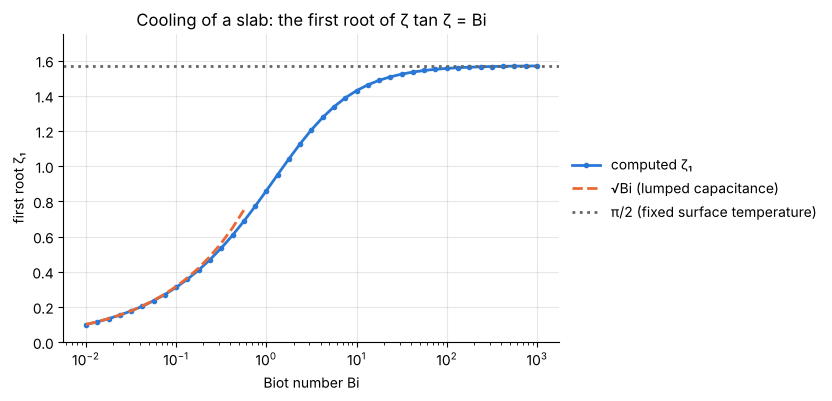

In [7]:
Bi_values = np.geomspace(1e-2, 1e3, 41)
zeta_1 = np.array([slab_modes(24, Bi, count=1)[0][0] for Bi in Bi_values])

# Verify the whole curve and its two limits
assert np.abs(zeta_1 - [zeta_exact(Bi, 1) for Bi in Bi_values]).max() < 1e-8
assert abs(zeta_1[0] ** 2 / Bi_values[0] - 1) < 0.01                # Bi → 0: ζ₁² → Bi
assert abs(zeta_1[-1] / (np.pi / 2) - 1) < 2e-3                     # Bi → ∞: ζ₁ → π/2

fig, ax = plt.subplots()
ax.semilogx(Bi_values, zeta_1, "o-", ms=3, label="computed ζ₁")
small = Bi_values < 0.6
ax.semilogx(Bi_values[small], np.sqrt(Bi_values[small]), "--", label="√Bi (lumped capacitance)")
ax.axhline(np.pi / 2, color="0.4", ls=":", label="π/2 (fixed surface temperature)")
ax.set(xlabel="Biot number Bi", ylabel="first root ζ₁", ylim=(0, 1.75), title="Cooling of a slab: the first root of ζ tan ζ = Bi")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

For small $\mathrm{Bi}$ the root follows $\zeta_1^2 = \mathrm{Bi}$: the plate is nearly
isothermal and cools at the rate set by the surface alone, which is the lumped-capacitance
model. For large $\mathrm{Bi}$ it approaches $\pi/2$, the root for a surface held at the fluid
temperature (the model problem of notebook 8), and conduction inside the plate is the only
resistance. In between, both matter and there is no shortcut.

After a short initial period only the first mode survives, and the mid-plane temperature of a
plate that starts at $\theta = 1$ is $\theta(0, t) \approx C_1 e^{-\zeta_1^2 t}$. This one-term
solution is what the Heisler charts plot. The coefficient is the projection of the initial
temperature on the first mode, $C_1 = \int_0^1\phi_1\,dx\,\big/\int_0^1\phi_1^2\,dx$ with
$\phi_1(0) = 1$, which the Clenshaw-Curtis weights evaluate directly from the computed mode.

In [8]:
phi = modes[:, 0] / modes[-1, 0]                           # first mode for Bi = 1, scaled to 1 at the mid-plane
w = clenshaw_curtis(24)[1] / 2                             # weights for [0, 1]
C1 = (w @ phi) / (w @ phi**2)
C1_exact = 4 * np.sin(zeta[0]) / (2 * zeta[0] + np.sin(2 * zeta[0]))
print(f"Bi = 1:  C₁ = {C1:.6f}   (formula {C1_exact:.6f}, tables give 1.1191)")
assert abs(C1 - C1_exact) < 1e-9 and abs(C1 - 1.1191) < 5e-5
t_half = np.log(2 * C1) / zeta[0] ** 2
print(f"time for the mid-plane temperature to fall to one half: t = {t_half:.3f} (in units of a²/α)")

Bi = 1:  C₁ = 1.119132   (formula 1.119132, tables give 1.1191)
time for the mid-plane temperature to fall to one half: t = 1.089 (in units of a²/α)


For a steel plate 4 cm thick ($a = 2$ cm, $\alpha = 1.2\times10^{-5}$ m²/s, time unit 33 s) with
$\mathrm{Bi} = 1$, the mid-plane excess temperature halves in 1.09 units, about 36 seconds.

## 13.4 Worked example: a plate with mixed boundary conditions

**Problem.** A square plate $-1 \le x, y \le 1$ conducts heat steadily, $\nabla^2 T = 0$. The
left side is held at $T = 0$. The right side is heated unevenly, hottest at mid-height:
$T(1, y) = \tfrac12(1 + \cos\pi y)$. The top and bottom are insulated, $\partial T/\partial y = 0$.
Find the temperature field, the paths along which heat flows, and the total heat flow.

**By hand.** Split the boundary data into its mean $\tfrac12$ and the variation
$\tfrac12\cos\pi y$. Each part has a separable solution that satisfies all four conditions:

$$T(x, y) = \frac{x + 1}{4} + \frac{\cos\pi y}{2}\,\frac{\sinh\pi(x+1)}{\sinh 2\pi} .$$

**The matrix.** Keep all $(N+1)^2$ grid values as unknowns, stored row by row as in notebook 6:
with `X, Y = np.meshgrid(x, x)`, the row index of the arrays is $y$ and the column index is $x$,
and `flatten()` strings the rows together. Then

- `np.kron(I, D)` differentiates with respect to $x$ and `np.kron(D, I)` with respect to $y$;
- the Laplacian is `np.kron(I, D2) + np.kron(D2, I)`, now with the full $D^2$.

Each row of this $(N+1)^2 \times (N+1)^2$ system belongs to one grid point. **To find the rows
of the boundary points, flatten the coordinate arrays in the same way and test them**: the rows
where `X.flatten() == 1` belong to the right side, and so on. Those rows are overwritten with
rows of the identity (Dirichlet) or of the $y$-derivative matrix (Neumann). The four corners
belong to two sides. They are given the Dirichlet condition, by applying it last.

In [9]:
def solve_plate(N):
    """Laplace equation on the square: T given on x = ±1, insulated on y = ±1. Returns x, T as (N+1) x (N+1), and pieces for later."""
    D, x = cheb(N)
    I, D2 = np.eye(N + 1), D @ D
    X, Y = np.meshgrid(x, x)                          # X[i, j] = x_j and Y[i, j] = y_i
    xf, yf = X.flatten(), Y.flatten()
    A = np.kron(I, D2) + np.kron(D2, I)               # Laplace equation in every row, for now
    rhs = np.zeros((N + 1) ** 2)
    identity, d_dy = np.eye((N + 1) ** 2), np.kron(D, I)

    insulated = np.abs(yf) == 1                       # rows of the top and bottom sides
    A[insulated] = d_dy[insulated]                    # ∂T/∂y = 0
    right, left = xf == 1, xf == -1                   # rows of the right and left sides, corners included
    A[right], rhs[right] = identity[right], (1 + np.cos(np.pi * yf[right])) / 2
    A[left], rhs[left] = identity[left], 0.0
    return x, np.linalg.solve(A, rhs).reshape(N + 1, N + 1), D, X, Y

plate_exact = lambda X, Y: (X + 1) / 4 + np.cos(np.pi * Y) / 2 * np.sinh(np.pi * (X + 1)) / np.sinh(2 * np.pi)

print("  N   unknowns   largest error")
for N in (8, 12, 16, 20):
    x, T, D, X, Y = solve_plate(N)
    print(f"{N:3d} {(N + 1) ** 2:8d} {np.abs(T - plate_exact(X, Y)).max():14.1e}")

  N   unknowns   largest error
  8       81        1.2e-04
 12      169        4.2e-08
 16      289        4.7e-12
 20      441        4.0e-13


**Heat flow lines.** The heat flux is $\mathbf{q} = -\nabla T$ (unit conductivity). Because
$\nabla\cdot\mathbf{q} = 0$, there is a heat function $H$ with $\partial H/\partial y = q_x$,
and heat flows along the lines $H = $ constant, with the same amount of heat between each pair
of neighbouring lines. $H$ is obtained by integrating $q_x = -\partial T/\partial x$ upwards
from the bottom side, where $H = 0$. Integration is the inverse of differentiation: delete the
row and column of the point $y = -1$ (index $N$) from $D$, and solve.

net heat flow through every vertical section: -0.5000000000 (negative: towards the cold side)
right side: 1.2627 enters through the hot middle (exact 1.2627), 0.7627 leaves again through its two ends


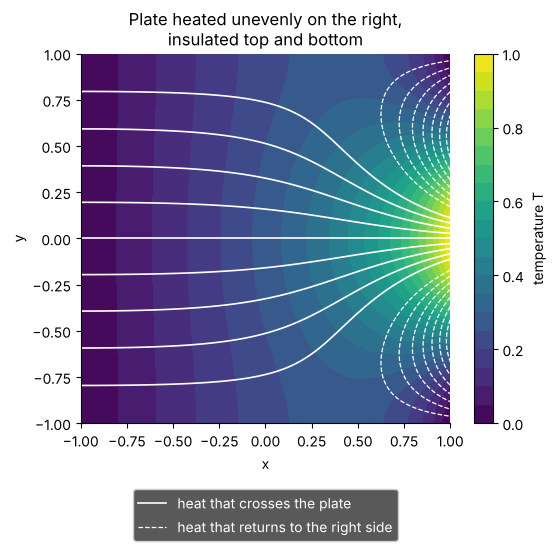

In [10]:
x, T, D, X, Y = solve_plate(20)
N = 20
q_x = -T @ D.T                                        # -∂T/∂x: D acts along the x index, the second one
H = np.zeros_like(T)
H[:N, :] = np.linalg.solve(D[:N, :N], q_x[:N, :])     # ∂H/∂y = q_x with H = 0 at y = -1 (row index N)
total_flow = H[0, :]                                  # H along the top side y = 1: the net heat crossing each vertical line

# evaluate interpolants on a fine uniform grid: P maps grid values to values at x_fine
x_fine = np.linspace(-1, 1, 161)
P = np.array([barycentric_interpolate(column, x_fine) for column in np.eye(N + 1)]).T

# heat through the right side x = 1 (column index 0): going up that side, H falls where heat enters and rises where it leaves
H_right = P @ H[:, 0]
entering = H_right.max() - H_right.min()
leaving = entering + total_flow.mean()                # what enters and does not cross the plate
y_turn = np.arccos(-np.tanh(2 * np.pi) / (2 * np.pi)) / np.pi         # ∂T/∂x = 0 at y = ±y_turn on the right side
entering_exact = y_turn / 2 + np.sin(np.pi * y_turn) / np.tanh(2 * np.pi)

# Verify: the exact solution, the insulation condition, and conservation of energy
assert np.abs(T - plate_exact(X, Y)).max() < 1e-10
assert np.abs((D @ T)[[0, N], :]).max() < 1e-9                         # ∂T/∂y = 0 on the top and bottom rows
assert np.abs(total_flow + 0.5).max() < 1e-10                          # the same heat flow, 0.5 to the left, through every section
assert abs(entering - entering_exact) < 1e-4 and abs(entering - 1.26) < 5e-3 and abs(leaving - 0.76) < 5e-3
print(f"net heat flow through every vertical section: {total_flow.mean():.10f} (negative: towards the cold side)")
print(f"right side: {entering:.4f} enters through the hot middle (exact {entering_exact:.4f}), {leaving:.4f} leaves again through its two ends")

fig, ax = plt.subplots(figsize=(6.2, 4.8))
image = ax.contourf(x_fine, x_fine, P @ T @ P.T, levels=np.linspace(0, 1, 21), cmap="viridis")
ax.contour(x_fine, x_fine, P @ H @ P.T, levels=np.linspace(-0.5, 0, 11)[1:-1], colors="w", linewidths=1.2, linestyles="solid")
returning = np.concatenate([np.arange(-0.85, -0.52, 0.05), np.arange(0.05, 0.38, 0.05)])    # H outside [-0.5, 0], same spacing
ax.contour(x_fine, x_fine, P @ H @ P.T, levels=returning, colors="w", linewidths=0.9, linestyles="dashed")
ax.plot([], [], color="w", lw=1.2, label="heat that crosses the plate")
ax.plot([], [], color="w", lw=0.9, ls="--", label="heat that returns to the right side")
ax.set(xlabel="x", ylabel="y", aspect="equal", title="Plate heated unevenly on the right,\ninsulated top and bottom")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), facecolor="0.35", labelcolor="w", framealpha=1)
fig.colorbar(image, label="temperature T", ticks=np.linspace(0, 1, 6));

With $21 \times 21$ points the error is below $10^{-12}$. The solid white lines divide the net
heat flow of 0.5 that reaches the cold side into ten equal parts. They leave the hot middle of
the right side, spread out, and arrive evenly spaced and perpendicular to the cold side. They
never cross the top and bottom sides, which is the insulation condition made visible.

Not all the heat that enters gets that far. Near its ends the right side is colder than the
plate next to it, so heat flows out there: 1.26 units enter through the hot middle, and 0.76
of them turn back and leave through the two ends of the same side (dashed lines, with the
same 0.05 between neighbours).

The net flow through every vertical section is exactly 0.5, the value for a right side at the
uniform temperature $\tfrac12$: the uneven part of the heating changes how much heat enters
and where, but not the net flow across the plate. That is a general property of this geometry
(the $\cos\pi y$ part carries no net flux), and it is the kind of check that an energy
balance provides for any conduction calculation.

## 13.5 Waves: fixed, free and absorbing ends

**Problem.** A string, or a bar carrying longitudinal waves, occupies $-1 \le x \le 1$ and obeys
$u_{tt} = u_{xx}$. A pulse $u = e^{-(x/0.12)^2}$ travels to the right and meets the end
$x = 1$. What comes back if the end is

- **fixed**, $u = 0$;
- **free**, $u_x = 0$ (no force on the end);
- **absorbing**, $u_t + u_x = 0$?

**By hand.** Every solution is a right-going plus a left-going wave,
$u = f(x - t) + g(x + t)$. At a fixed end $g$ must cancel $f$: the reflection is the mirror
image of the pulse with the sign changed. At a free end the slopes must cancel, and the
reflection is the mirror image with the same sign. The third condition is satisfied by every
right-going wave, since $(\partial_t + \partial_x)f(x - t) = 0$, and by no left-going wave. It
lets the pulse out and sends nothing back. In all cases the energy
$E = \tfrac12\int(u_t^2 + u_x^2)\,dx$ can leave only through an absorbing end.

**Boundary rows for a time-dependent problem.** Write the equation as a first-order system for
$u$ and $v = u_t$, as in notebook 9: $u_t = v$, $v_t = D^2 u$. The boundary rows of this system
of ordinary differential equations are replaced as follows (index 0 is the end $x = 1$).

- Fixed: $du_0/dt = 0$ and $dv_0/dt = 0$.
- Absorbing: the condition is itself an evolution equation for the boundary value,
  $du_0/dt = -(D\mathbf{u})_0$, and its time derivative gives $dv_0/dt = -(D\mathbf{v})_0$.
- Free: $(D\mathbf{u})_0 = 0$ contains no time derivative. It is an algebraic constraint, and
  the boundary value is eliminated with it: $u_0 = -\sum_{j \ge 1} D_{0j}u_j / D_{00}$. The matrix
  $E$ below performs this substitution.

The left end is fixed in all three cases.

In [11]:
def wave_system(N, right_end):
    """Matrix M of d/dt [u; v] = M [u; v] for u_tt = u_xx: left end fixed, right end 'fixed', 'free' or 'absorbing'."""
    D, x = cheb(N)
    D2, n = D @ D, N + 1
    zero, I = np.zeros((n, n)), np.eye(n)
    if right_end == "free":
        E = np.eye(n)                                 # E u: the same values, with u_0 replaced by the value that makes (Du)_0 = 0
        E[0, :] = -D[0, :] / D[0, 0]
        E[0, 0] = 0.0
        M = np.block([[zero, E], [E @ D2 @ E, zero]])
    else:
        M = np.block([[zero, I], [D2, zero]])
        M[0, :] = M[n, :] = 0.0                       # rows of u_0 and v_0: fixed end
        if right_end == "absorbing":
            M[0, :n] = -D[0, :]                       # du_0/dt = -(Du)_0
            M[n, n:] = -D[0, :]                       # dv_0/dt = -(Dv)_0
    M[N, :] = M[n + N, :] = 0.0                       # rows of u_N and v_N: the left end x = -1 is fixed
    return M, D, x

def rk4_step(f, u, dt):                               # from notebook 9
    k1 = f(u)
    k2 = f(u + dt / 2 * k1)
    k3 = f(u + dt / 2 * k2)
    k4 = f(u + dt * k3)
    return u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

**Stability first.** Boundary conditions change the eigenvalues of the semi-discrete system,
and a careless treatment can create eigenvalues with positive real part, which no time step
can cure. By the rule of notebook 9, check the spectrum before marching: no eigenvalue may lie
in the right half-plane, and RK4 needs $|\lambda|\,\Delta t < 2.83$ for those on the imaginary
axis.

In [12]:
N = 80
spectrum = {kind: np.linalg.eigvals(wave_system(N, kind)[0]) for kind in ("fixed", "free", "absorbing")}
print("right end    largest Re λ    largest |λ|    RK4 step used")
for kind, values in spectrum.items():
    print(f"{kind:10s} {values.real.max():13.1e} {np.abs(values).max():13.1f} {2 / np.abs(values).max():14.2e}")
    assert values.real.max() < 1e-8                                    # nothing in the right half-plane
assert np.abs(spectrum["fixed"].real).max() < 1e-8                     # reflecting ends: purely imaginary spectrum
assert spectrum["absorbing"].real.min() < -1                           # an absorbing end damps

right end    largest Re λ    largest |λ|    RK4 step used
fixed            5.7e-14        1393.5       1.44e-03
free             3.2e-14        1393.3       1.44e-03
absorbing        0.0e+00        2133.5       9.37e-04


In [13]:
def run_wave(right_end, t_end=2.0, store_every=10):
    """RK4 from the right-moving pulse. Returns x, the final u, the energy history, and snapshots of u with their times."""
    M, D, x = wave_system(N, right_end)
    weights = clenshaw_curtis(N)[1]
    energy_of = lambda W: 0.5 * weights @ (W[N + 1:] ** 2 + (D @ W[:N + 1]) ** 2)
    u0 = np.exp(-(x / 0.12) ** 2)
    W = np.concatenate([u0, 2 * x / 0.12**2 * u0])                     # v = u_t = -u_x for a right-moving pulse
    n_steps = int(np.ceil(t_end * np.abs(spectrum[right_end]).max() / 2))
    dt = t_end / n_steps
    energy, snapshots, times = [energy_of(W)], [W[:N + 1]], [0.0]
    for step in range(1, n_steps + 1):
        W = rk4_step(lambda q: M @ q, W, dt)
        energy.append(energy_of(W))
        if step % store_every == 0 or step == n_steps:
            snapshots.append(W[:N + 1])
            times.append(step * dt)
    return x, W[:N + 1], np.array(energy), np.array(snapshots), np.array(times), u0

results = {kind: run_wave(kind) for kind in ("fixed", "free", "absorbing")}

print("right end    energy at t = 2 / initial    largest |u(x, 2) − expected|")
expected_sign = {"fixed": -1, "free": 1, "absorbing": 0}
for kind, (x, u_end, energy, _, _, u0) in results.items():
    print(f"{kind:10s} {energy[-1] / energy[0]:20.3e} {np.abs(u_end - expected_sign[kind] * u0).max():24.1e}")

right end    energy at t = 2 / initial    largest |u(x, 2) − expected|
fixed                 1.000e+00                  8.7e-08
free                  1.000e+00                  8.7e-08
absorbing             5.061e-19                  7.2e-11


**Verify.** The pulse starts at the centre, reaches the end at $t = 1$, and at $t = 2$ its
reflection is back at the centre. So at $t = 2$ the exact solution is $-u(x, 0)$ for the fixed
end, $+u(x, 0)$ for the free end and zero for the absorbing end.

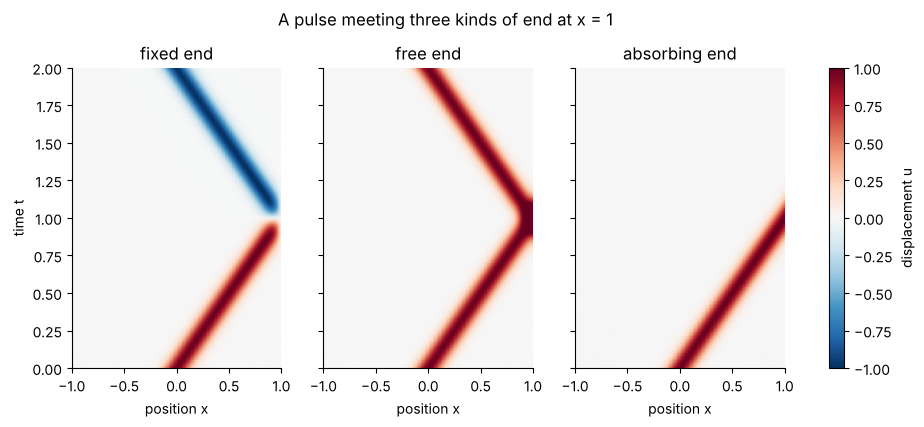

In [14]:
for kind in ("fixed", "free"):
    x, u_end, energy, _, _, u0 = results[kind]
    assert np.abs(energy / energy[0] - 1).max() < 1e-7                 # energy conserved in the reflecting cases
    assert np.abs(u_end - expected_sign[kind] * u0).max() < 1e-6       # mirror image with the right sign
x, u_end, energy, _, _, u0 = results["absorbing"]
assert energy[-1] / energy[0] < 1e-12 and np.abs(u_end).max() < 1e-8   # the pulse has left
assert energy.max() < energy[0] * (1 + 1e-8)                           # and the energy never exceeds its initial value by more than the time-stepping error

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9), sharey=True)
for ax, (kind, (x, _, _, snapshots, times, _)) in zip(axes, results.items()):
    image = ax.pcolormesh(x, times, snapshots, cmap="RdBu_r", vmin=-1, vmax=1, shading="gouraud")
    ax.set(title=f"{kind} end", xlabel="position x")
    ax.grid(False)
axes[0].set_ylabel("time t")
fig.suptitle("A pulse meeting three kinds of end at x = 1", x=0.45, y=1.03)
fig.colorbar(image, ax=axes, label="displacement u");

The three panels show the pulse in the $x$-$t$ plane, moving right until it meets the end at
$t = 1$. From the fixed end it returns upside down (blue), from the free end the right way up
(red), and at the absorbing end it leaves the domain. The energy is conserved to $10^{-8}$ in
the reflecting cases, and after the pulse has left through the absorbing end less than
$10^{-15}$ of it remains.

These are the three standard terminations of every wave-bearing system: a clamped string or a
closed organ pipe (in terms of displacement), a free bar end or an open pipe, and a matched
load, the impedance-matched terminator of a cable or the anechoic lining of a duct. In
simulations the absorbing condition is what allows a finite grid to stand in for an unbounded
medium. In one dimension it is exact; in two and three dimensions it is exact only for waves
that hit the boundary head-on, and designing better ones is a subject of its own.

## Summary

- Keep the boundary values as unknowns and replace the boundary rows: a row of the identity
  for Dirichlet, a row of $D$ for Neumann, their combination for Robin. Remember that index 0
  is $x = +1$.
- The derivative in a boundary row is spectrally accurate. Neumann and Robin problems converge
  as fast as Dirichlet problems.
- In an eigenvalue problem the boundary rows carry no eigenvalue: solve
  $A\mathbf{u} = \lambda B\mathbf{u}$ with zero rows in $B$ and discard the infinite eigenvalues.
- In two dimensions, find the rows of the Kronecker system by testing the flattened coordinate
  arrays, and decide which condition the corners get.
- In time-dependent problems a boundary condition is either an evolution equation for the
  boundary value or a constraint that eliminates it. Check the eigenvalues of the resulting
  system before choosing a time step.

## Exercises

1. A rod on $0 \le x \le 1$ with internal heating obeys $\theta'' + e^{2x} = 0$. A heater
   supplies the flux $-\theta'(0) = 2$ at the left end and the right end is held at
   $\theta(1) = 0$. Solve with $N = 16$ using a Neumann row and a Dirichlet row, find the exact
   solution by integrating twice, and report the largest error and the temperature at $x = 0$.
2. Critical radius of insulation. A pipe of outer radius 1 at $\theta = 1$ is covered with
   insulation out to radius $r_o$, whose surface loses heat by convection:
   $\theta'' + \theta'/r = 0$ on $1 \le r \le r_o$, $\theta(1) = 1$,
   $\theta'(r_o) + \mathrm{Bi}\,\theta(r_o) = 0$ with $\mathrm{Bi} = 0.25$. Solve on a Chebyshev
   grid mapped to $[1, r_o]$ with $N = 16$ for $r_o = 1.5, 2, 2.5, \dots, 8$, and compute the
   heat loss per unit length $Q = -2\pi\,\theta'(1)$ for each. Compare with the exact
   $Q = 2\pi/\big(\ln r_o + 1/(\mathrm{Bi}\,r_o)\big)$. At which $r_o$ is the loss largest, and
   how does it compare with the loss from the bare pipe, $2\pi\,\mathrm{Bi}$?
3. A vertical column clamped at its base and free at the top buckles under its own weight when
   the eigenvalue problem $\theta'' + \lambda\,x\,\theta = 0$ on $0 \le x \le 1$, with
   $\theta'(0) = 0$ at the free top and $\theta(1) = 0$ at the base, has a non-zero solution.
   Here $\theta$ is the slope of the column and $\lambda = qL^3/EI$, with $q$ the weight per
   unit length. Formulate it as a generalized eigenvalue problem with one Neumann and one
   Dirichlet row and compute the smallest $\lambda$. The classical value is 7.8373. How tall
   can a steel tube be ($E = 200$ GPa, outer diameter 50 mm, wall thickness 2 mm, density
   7850 kg/m³, $g = 9.81$ m/s²) before it buckles under its own weight?
4. A bar carrying longitudinal waves is fixed at $x = 0$ and attached to a spring at $x = 1$:
   $-u'' = \mu^2 u$, $u(0) = 0$, $u'(1) + 2u(1) = 0$. Compute the first three natural
   frequencies $\mu$ with $N = 24$ and check them against the roots of the transcendental
   equation you derive by hand. Between which two classical cases (free end, fixed end) do they
   lie?
5. A dashpot at the end $x = 1$ of the string of 13.5 gives the condition
   $u_x + \beta\,u_t = 0$. Show by hand that a pulse is reflected with its amplitude multiplied
   by $(1 - \beta)/(1 + \beta)$, so that $\beta = 0$, $1$ and $\infty$ are the free, absorbing
   and fixed ends. Modify `wave_system` for this condition, run the pulse of 13.5 to $t = 2$
   with $\beta = 3$ and $N = 80$, and confirm that one quarter of the energy remains and that
   $u(x, 2) = -\tfrac12 u(x, 0)$.